# DATA COLLECTION FROM PUBCHEM DATABASE

In [3]:
import pandas as pd
import glob
import os

# 1. Thiết lập đường dẫn đến thư mục chứa file CSV
path = 'Raw_data_PubChem' # Tên thư mục chứa file của bạn
all_files = glob.glob(os.path.join(path, "*.csv"))

# 2. Đọc và gộp tất cả các file vào một danh sách
li = []
for filename in all_files:
    # Đọc file, bỏ qua lỗi nếu file trống hoặc lỗi encoding
    df = pd.read_csv(filename, index_col=None, header=0)
    li.append(df)

# 3. Gộp tất cả DataFrames trong danh sách thành 1 file duy nhất
df_Raw_data_PubChem = pd.concat(li, axis=0, ignore_index=True)

# 4. Lưu kết quả ra file mới
df_Raw_data_PubChem.to_csv('combined_MRSA_data_PubChem.csv', index=False, encoding='utf-8-sig')

print(f"Đã gộp thành công {len(all_files)} file vào 'combined_MRSA_data_PubChem.csv'")
print(f"Tổng số dòng dữ liệu: {len(df_Raw_data_PubChem)}")
df_Raw_data_PubChem.info()

Đã gộp thành công 1 file vào 'combined_MRSA_data_PubChem.csv'
Tổng số dòng dữ liệu: 32384
<class 'pandas.DataFrame'>
RangeIndex: 32384 entries, 0 to 32383
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   PUBCHEM_RESULT_TAG             32384 non-null  str    
 1   PUBCHEM_SID                    24548 non-null  float64
 2   PUBCHEM_CID                    24526 non-null  float64
 3   PUBCHEM_EXT_DATASOURCE_SMILES  24526 non-null  str    
 4   PUBCHEM_ACTIVITY_OUTCOME       24548 non-null  str    
 5   PUBCHEM_ACTIVITY_SCORE         0 non-null      float64
 6   PUBCHEM_ACTIVITY_URL           0 non-null      float64
 7   PUBCHEM_ASSAYDATA_COMMENT      2144 non-null   str    
 8   Standard Type                  31556 non-null  str    
 9   Activity Comment               4347 non-null   str    
 10  Standard Relation              27749 non-null  str    
 11  Standard Value             

In [4]:
# Chuyển đổi cột 'Standard Value' về kiểu float64 do dữ liệu ban đầu có thể là String
import pandas as pd

# Chuyển đổi cột Standard Value về float64
df_Raw_data_PubChem['Standard Value'] = pd.to_numeric(df_Raw_data_PubChem['Standard Value'], errors='coerce')

# Kiểm tra lại kiểu dữ liệu của cột
print(df_Raw_data_PubChem['Standard Value'].dtype)
df_Raw_data_PubChem.info()

float64
<class 'pandas.DataFrame'>
RangeIndex: 32384 entries, 0 to 32383
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   PUBCHEM_RESULT_TAG             32384 non-null  str    
 1   PUBCHEM_SID                    24548 non-null  float64
 2   PUBCHEM_CID                    24526 non-null  float64
 3   PUBCHEM_EXT_DATASOURCE_SMILES  24526 non-null  str    
 4   PUBCHEM_ACTIVITY_OUTCOME       24548 non-null  str    
 5   PUBCHEM_ACTIVITY_SCORE         0 non-null      float64
 6   PUBCHEM_ACTIVITY_URL           0 non-null      float64
 7   PUBCHEM_ASSAYDATA_COMMENT      2144 non-null   str    
 8   Standard Type                  31556 non-null  str    
 9   Activity Comment               4347 non-null   str    
 10  Standard Relation              27749 non-null  str    
 11  Standard Value                 22339 non-null  float64
 12  Standard Units                 26359 non-null  st

In [5]:
# Chỉ xóa dòng nếu cột 'Standard value', 'Standard unit', 'Smiles', 'Molecular Weight' bị NaN
df_subset_PubChem =df_Raw_data_PubChem.dropna(subset=['Standard Value', 'Standard Units','PUBCHEM_EXT_DATASOURCE_SMILES', 'Standard Relation']).copy()
print (df_subset_PubChem.info())

<class 'pandas.DataFrame'>
Index: 21568 entries, 12 to 32383
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   PUBCHEM_RESULT_TAG             21568 non-null  str    
 1   PUBCHEM_SID                    21568 non-null  float64
 2   PUBCHEM_CID                    21568 non-null  float64
 3   PUBCHEM_EXT_DATASOURCE_SMILES  21568 non-null  str    
 4   PUBCHEM_ACTIVITY_OUTCOME       21568 non-null  str    
 5   PUBCHEM_ACTIVITY_SCORE         0 non-null      float64
 6   PUBCHEM_ACTIVITY_URL           0 non-null      float64
 7   PUBCHEM_ASSAYDATA_COMMENT      0 non-null      str    
 8   Standard Type                  21568 non-null  str    
 9   Activity Comment               14 non-null     str    
 10  Standard Relation              21568 non-null  str    
 11  Standard Value                 21568 non-null  float64
 12  Standard Units                 21568 non-null  str    
 13  P

In [6]:
# Ở cột 'Standard Type', chỉ giữ lại các dòng có giá trị 'MIC'
df_subset_MIC_PubChem = df_subset_PubChem[df_subset_PubChem['Standard Type'] == 'MIC'].copy()
print (df_subset_MIC_PubChem.info())

<class 'pandas.DataFrame'>
Index: 17110 entries, 12 to 32383
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   PUBCHEM_RESULT_TAG             17110 non-null  str    
 1   PUBCHEM_SID                    17110 non-null  float64
 2   PUBCHEM_CID                    17110 non-null  float64
 3   PUBCHEM_EXT_DATASOURCE_SMILES  17110 non-null  str    
 4   PUBCHEM_ACTIVITY_OUTCOME       17110 non-null  str    
 5   PUBCHEM_ACTIVITY_SCORE         0 non-null      float64
 6   PUBCHEM_ACTIVITY_URL           0 non-null      float64
 7   PUBCHEM_ASSAYDATA_COMMENT      0 non-null      str    
 8   Standard Type                  17110 non-null  str    
 9   Activity Comment               0 non-null      str    
 10  Standard Relation              17110 non-null  str    
 11  Standard Value                 17110 non-null  float64
 12  Standard Units                 17110 non-null  str    
 13  P

In [7]:
df_subset_MIC_PubChem['Standard Units'].value_counts()

Standard Units
ug.mL-1    15872
nM          1194
U ml-1        35
10^-3mM        8
%              1
Name: count, dtype: int64

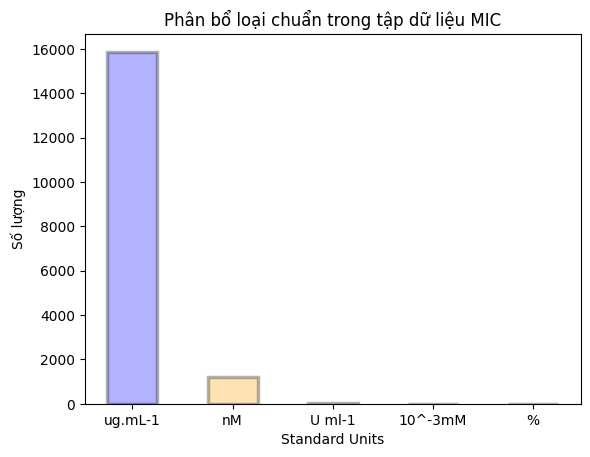

In [8]:
# Vizualize the distribution of 'Standard Units' in the dataset
import matplotlib.pyplot as plt

df_subset_MIC_PubChem['Standard Units'].value_counts()
plt.bar(df_subset_MIC_PubChem['Standard Units'].value_counts().index, # lấy các giá trị duy nhất của 'Standard Units' làm nhãn trên trục x
        df_subset_MIC_PubChem['Standard Units'].value_counts().values, # lấy số lượng tương ứng của mỗi giá trị làm chiều cao của cột
        color=['blue', 'orange', 'green', 'red', 'purple'],  # màu sắc cho mỗi cột
        width=0.5, # độ rộng của cột
        edgecolor='black', # màu viền của cột
        alpha=0.3, # độ trong suốt của cột (0-1)
        align='center',
        linewidth=2.5) # độ dày của viền cột
    


plt.title('Phân bổ loại chuẩn trong tập dữ liệu MIC')
plt.ylabel('Số lượng')
plt.xlabel('Standard Units')
plt.xticks(rotation=0);

In [9]:
# Chỉ xóa các đơn vị khác ngoài nM và ug.ml-1
df_subset_MIC_PubChem = df_subset_MIC_PubChem[(df_subset_MIC_PubChem['Standard Units'] == 'nM') |  
                                              (df_subset_MIC_PubChem['Standard Units'] == 'ug.mL-1')].copy()
print (df_subset_MIC_PubChem.info())

<class 'pandas.DataFrame'>
Index: 17066 entries, 12 to 32383
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   PUBCHEM_RESULT_TAG             17066 non-null  str    
 1   PUBCHEM_SID                    17066 non-null  float64
 2   PUBCHEM_CID                    17066 non-null  float64
 3   PUBCHEM_EXT_DATASOURCE_SMILES  17066 non-null  str    
 4   PUBCHEM_ACTIVITY_OUTCOME       17066 non-null  str    
 5   PUBCHEM_ACTIVITY_SCORE         0 non-null      float64
 6   PUBCHEM_ACTIVITY_URL           0 non-null      float64
 7   PUBCHEM_ASSAYDATA_COMMENT      0 non-null      str    
 8   Standard Type                  17066 non-null  str    
 9   Activity Comment               0 non-null      str    
 10  Standard Relation              17066 non-null  str    
 11  Standard Value                 17066 non-null  float64
 12  Standard Units                 17066 non-null  str    
 13  P

In [10]:
# Tính khối lượng phân tử chính xác sử dụng RDKit
from rdkit import Chem
from rdkit.Chem import Descriptors

def calculate_mw(smiles):
    try:
        mol = Chem.MolFromSmiles(smiles)
        if mol:
            # Tính toán khối lượng phân tử chính xác từ cấu trúc
            return Descriptors.MolWt(mol)
    except:
        return None
    return None

# Áp dụng tính MW cho DataFrame
df_subset_MIC_PubChem['MW_RDKit'] = df_subset_MIC_PubChem['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(calculate_mw)
df_subset_MIC_PubChem[['PUBCHEM_EXT_DATASOURCE_SMILES', 'MW_RDKit', 'Standard Value']].head(10)

,PUBCHEM_EXT_DATASOURCE_SMILES,MW_RDKit,Standard Value
12,C1CC2=C(C=CC(=C2)O)C3=C(C=C(CCC4=CC(=C(C=C4)O)...,424.496,2.0
13,C1CC2=C(C=CC(=C2)O)C3=C(C=C(CCC4=CC(=CC=C4)OC5...,408.497,1.0
14,C1CC2=CC=CC=C2C3=C(C=C(CCC4=CC(=C(C=C4)O)OC5=C...,408.497,1.0
27,C1=CC=C(C=C1)OC2=CC=CC=C2O,186.210,8.0
28,C1CC2=C(C=CC(=C2)O)C3=C(C=C(CCC4=CC(=C(C=C4)O)...,424.496,2.0
29,C1CC2=C(C=CC(=C2)O)C3=C(C=C(CCC4=CC(=CC=C4)OC5...,408.497,1.0
30,C1CC2=CC=CC=C2C3=C(C=C(CCC4=CC(=C(C=C4)O)OC5=C...,408.497,1.0
31,C1CC2=C(C3=C(C=C(CCC4=CC(=C(C=C4)O)OC5=CC=C1C=...,424.496,4.0
32,C1CC2=CC(=C(C=C2)O)OC3=C(C=C(CCC4=C(C=CC(=C4)O...,440.495,8.0
33,C1CC2=CC(=C(C=C2)O)OC3=CC(=C(CCC4=C(C=CC(=C4)O...,440.495,8.0


In [11]:
df_subset_MIC_PubChem.info()

<class 'pandas.DataFrame'>
Index: 17066 entries, 12 to 32383
Data columns (total 17 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   PUBCHEM_RESULT_TAG             17066 non-null  str    
 1   PUBCHEM_SID                    17066 non-null  float64
 2   PUBCHEM_CID                    17066 non-null  float64
 3   PUBCHEM_EXT_DATASOURCE_SMILES  17066 non-null  str    
 4   PUBCHEM_ACTIVITY_OUTCOME       17066 non-null  str    
 5   PUBCHEM_ACTIVITY_SCORE         0 non-null      float64
 6   PUBCHEM_ACTIVITY_URL           0 non-null      float64
 7   PUBCHEM_ASSAYDATA_COMMENT      0 non-null      str    
 8   Standard Type                  17066 non-null  str    
 9   Activity Comment               0 non-null      str    
 10  Standard Relation              17066 non-null  str    
 11  Standard Value                 17066 non-null  float64
 12  Standard Units                 17066 non-null  str    
 13  P

In [12]:
# Chuyển đổi dữ liệu nồng độ về micromolar (uM)
def convert_to_uM(row): # Tao hàm nhận một dòng (row) của DataFrame
    val = row['Standard Value'] # Tùy thuộc vào các cột trong DataFrame mà có thể cần điều chỉnh tên cột
    unit = str(row['Standard Units']).strip().lower() # "Hàm strip" để loại bỏ khoảng trắng thừa và "hàm lower" chuyển về chữ thường
    mw = row['MW_RDKit']
    
    if pd.isna(val) or val <= 0 or pd.isna(mw): # Kiểm tra giá trị hợp lệ (isna dùng để kiểm tra giá trị null)
        return None

    # 1. Nhóm Micromolar (Giữ nguyên)
    if unit in ['um', 'u m', 'micromolar', '10^-6m', '10^-3mm']:
        return val
    
    # 2. Nhóm Nanomolar (Chia 1000)
    if unit in ['nm', 'n m', 'nanomolar', '10^-9m']:
        return val / 1000
    
    # 3. Nhóm Millimolar (Nhân 1000)
    if unit in ['mm', 'm m', 'millimolar', '10^-3m']:
        return val * 1000
    
    # 4. Nhóm Khối lượng (Cần MW)
    mass_to_um_factor1000 = ['ug/ml', 'ug.ml-1', 'ug ml-1', 'u ml-1', 'ug/m l', 'mg/l', 'mg.l-1']
    if any(mu in unit for mu in mass_to_um_factor1000):
        return (val * 1000) / mw
            
    return None
# Áp dụng hàm chuyển đổi cho DataFrame
df_subset_MIC_PubChem['Standard Value'] = df_subset_MIC_PubChem.apply(convert_to_uM, axis=1) # Gán đè lên cột Standard Value cũ

# Cập nhật luôn cột đơn vị để tránh nhầm lẫn sau này
df_subset_MIC_PubChem['Standard Units'] = 'uM'
df_subset_MIC_PubChem[['Standard Value', 'Standard Units']].sort_values(by='Standard Value', ascending=False).head(10)

,Standard Value,Standard Units
16119,170918.258343,uM
16122,170918.258343,uM
16125,170918.258343,uM
3094,50000.000000,uM
3092,50000.000000,uM
16117,9603.172888,uM
19743,7540.021018,uM
16113,4968.919409,uM
10538,3431.899912,uM
10490,3431.899912,uM


In [13]:
df_subset_MIC_PubChem.head()

,PUBCHEM_RESULT_TAG,PUBCHEM_SID,PUBCHEM_CID,PUBCHEM_EXT_DATASOURCE_SMILES,PUBCHEM_ACTIVITY_OUTCOME,PUBCHEM_ACTIVITY_SCORE,PUBCHEM_ACTIVITY_URL,PUBCHEM_ASSAYDATA_COMMENT,Standard Type,Activity Comment,Standard Relation,Standard Value,Standard Units,PubChem Standard Value,Standard Text Value,Data Validity Comment,MW_RDKit
12,2,103569944.0,10070992.0,C1CC2=C(C=CC(=C2)O)C3=C(C=C(CCC4=CC(=C(C=C4)O)...,Unspecified,NaN,NaN,NaN,MIC,NaN,=,4.711470,uM,NaN,NaN,NaN,424.496
13,3,103570173.0,24860513.0,C1CC2=C(C=CC(=C2)O)C3=C(C=C(CCC4=CC(=CC=C4)OC5...,Unspecified,NaN,NaN,NaN,MIC,NaN,=,2.447998,uM,NaN,NaN,NaN,408.497
14,4,103570206.0,24860511.0,C1CC2=CC=CC=C2C3=C(C=C(CCC4=CC(=C(C=C4)O)OC5=C...,Unspecified,NaN,NaN,NaN,MIC,NaN,=,2.447998,uM,NaN,NaN,NaN,408.497
27,2,103394255.0,75491.0,C1=CC=C(C=C1)OC2=CC=CC=C2O,Unspecified,NaN,NaN,NaN,MIC,NaN,=,42.962247,uM,NaN,NaN,NaN,186.210
28,3,103569944.0,10070992.0,C1CC2=C(C=CC(=C2)O)C3=C(C=C(CCC4=CC(=C(C=C4)O)...,Unspecified,NaN,NaN,NaN,MIC,NaN,=,4.711470,uM,NaN,NaN,NaN,424.496


In [76]:
# Lưu dataframe df_subset ra file
df_subset_MIC_PubChem.to_excel('RDKit_MIC_PubChem.xlsx', index=False, sheet_name='Data_Cleaned_MIC_PubChem')

print("Done!")

Done!


In [ ]:
# Đếm số lần trùng lặp của cột 'PUBCHEM_EXT_DATASOURCE_SMILES'
counts = df_subset_MIC_PubChem['PUBCHEM_EXT_DATASOURCE_SMILES'].value_counts()
duplicate = counts[counts >= 2].index.tolist() # Lấy danh sách các giá trị bị trùng lặp
print(f"Số lượng chất bị lặp: {len(duplicate)}")
#num_duplicates = counts[counts >= 2].sum() # Lấy tổng trừ số này sẽ ra số chất bị lặp 

Số lượng chất bị lặp: 1751


In [24]:
df_subset_MIC_PubChem['PUBCHEM_EXT_DATASOURCE_SMILES'].duplicated().sum()

np.int64(14926)

C:\Users\Nhat Truong\AppData\Local\Temp\ipykernel_9796\1797694891.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=smile_counts.values, y=ids, palette='viridis', legend=False);


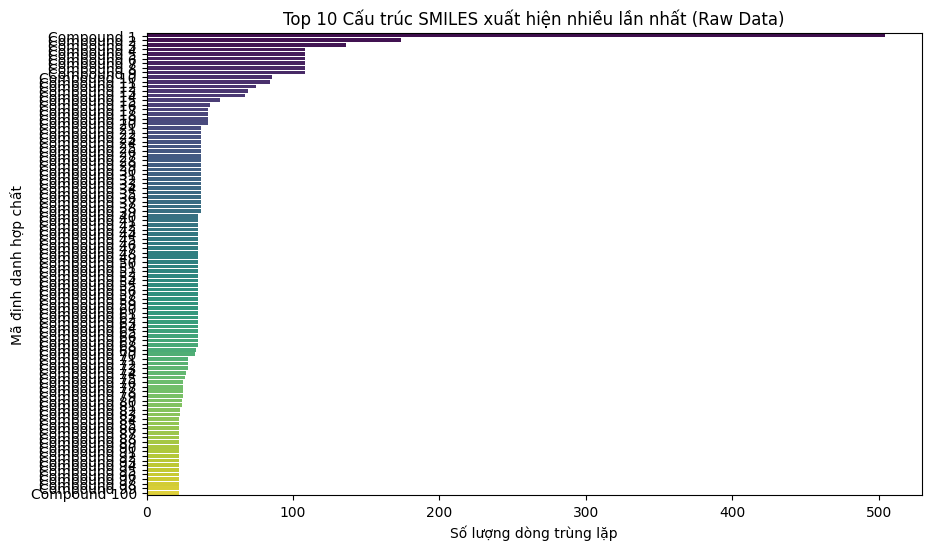

In [15]:
# Visualize the duplicate SMILES with different MIC values
import matplotlib.pyplot as plt
import seaborn as sns

# Đếm tần suất và lấy Top 10
smile_counts = df_subset_MIC_PubChem['PUBCHEM_EXT_DATASOURCE_SMILES'].value_counts().head(100);
# Tạo ID ngắn cho dễ nhìn (thay vì để SMILES quá dài)
ids = [f"Compound {i+1}" for i in range(len(smile_counts))];

plt.figure(figsize=(10, 6));
sns.barplot(x=smile_counts.values, y=ids, palette='viridis', legend=False);
plt.title('Top 10 Cấu trúc SMILES xuất hiện nhiều lần nhất (Raw Data)');
plt.xlabel('Số lượng dòng trùng lặp');
plt.ylabel('Mã định danh hợp chất');
plt.show;

In [19]:
df_subset['PUBCHEM_EXT_DATASOURCE_SMILES'].value_counts().sort_values(ascending=False).head(50)

PUBCHEM_EXT_DATASOURCE_SMILES
C[C@H]1[C@H]([C@@](C[C@@H](O1)O[C@@H]2[C@H]([C@@H]([C@H](O[C@H]2OC3=C4C=C5C=C3OC6=C(C=C(C=C6)[C@H]([C@H](C(=O)N[C@H](C(=O)N[C@H]5C(=O)N[C@@H]7C8=CC(=C(C=C8)O)C9=C(C=C(C=C9O)O)[C@H](NC(=O)[C@H]([C@@H](C1=CC(=C(O4)C=C1)Cl)O)NC7=O)C(=O)O)CC(=O)N)NC(=O)[C@@H](CC(C)C)NC)O)Cl)CO)O)O)(C)N)O    504
CCCCCCCCCNC1=C(C(=C(C=C1)F)C(=O)N)F                                                                                                                                                                                                                                                             174
C1CC1N2C=C(C(=O)C3=CC(=C(C=C32)N4CCNCC4)F)C(=O)O                                                                                                                                                                                                                                                136
C1COCCN1CCCCCOC(=O)C2=C3C=CC(=CN3C4=C2C(=O)C5=C(C4=O)N=CC=C5)Br                               

(np.float64(-0.6400000000000001),
 np.float64(4.640000000000001),
 np.float64(-2499.9992077791567),
 np.float64(52499.9999622752))

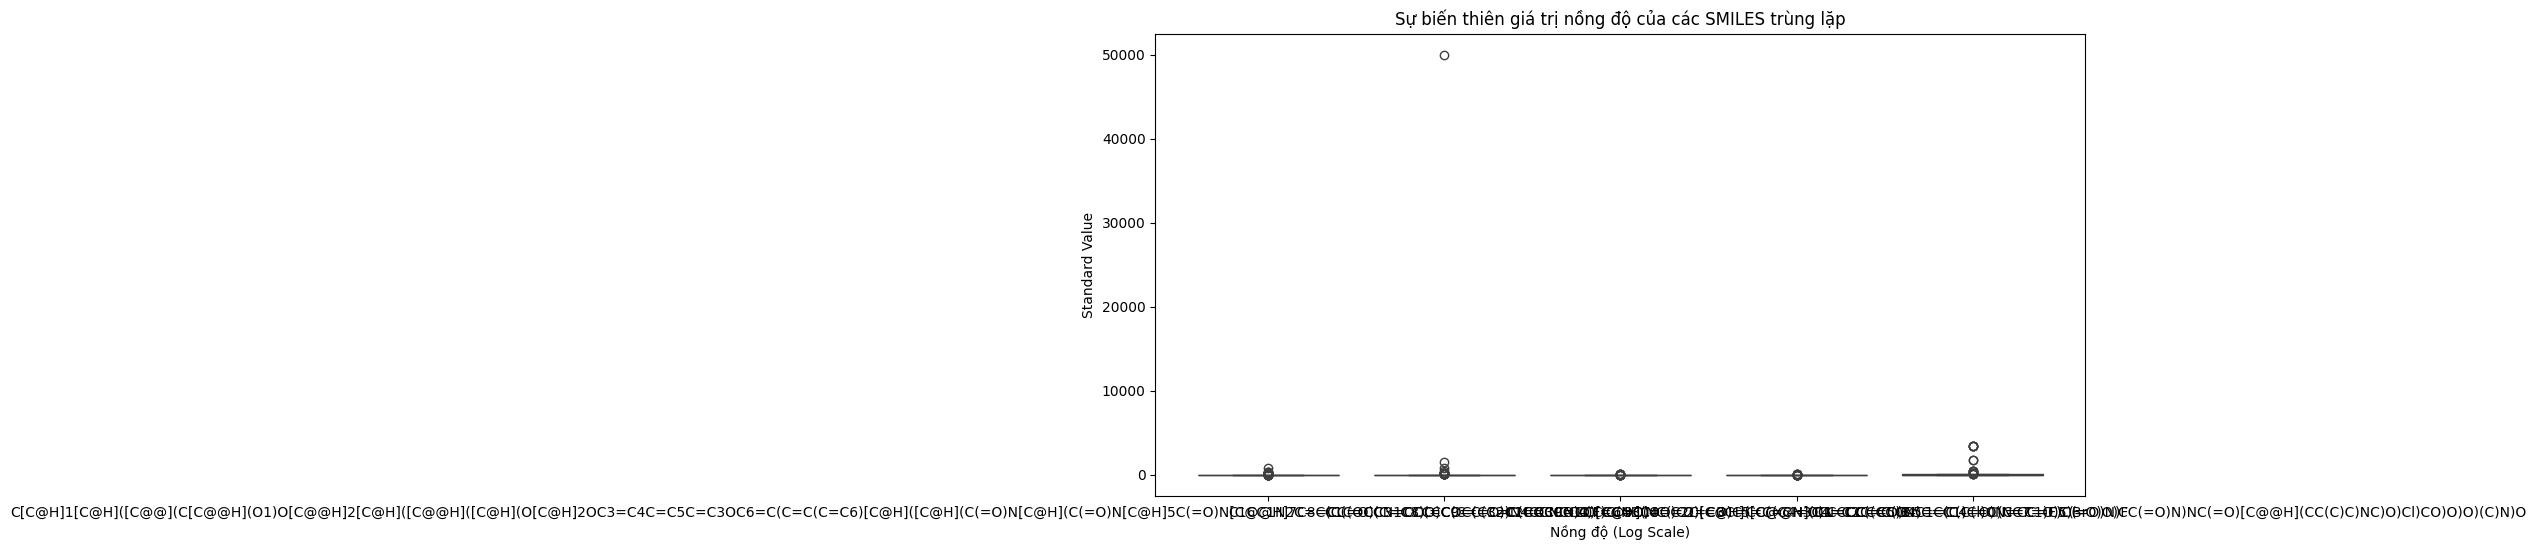

In [16]:
# Lọc lấy dữ liệu của 5 hợp chất bị trùng nhiều nhất
top_5_smiles = df_subset_MIC_PubChem['PUBCHEM_EXT_DATASOURCE_SMILES'].value_counts().head(5).index
df_subset = df_subset_MIC_PubChem[df_subset_MIC_PubChem['PUBCHEM_EXT_DATASOURCE_SMILES'].isin(top_5_smiles)]

plt.figure(figsize=(12, 6))
# Sử dụng log scale vì nồng độ thường trải dài nhiều bậc thập phân
sns.boxplot(data=df_subset, x='PUBCHEM_EXT_DATASOURCE_SMILES', y='Standard Value')
plt.title('Sự biến thiên giá trị nồng độ của các SMILES trùng lặp')
plt.xlabel('Nồng độ (Log Scale)')
plt.axis("tight")

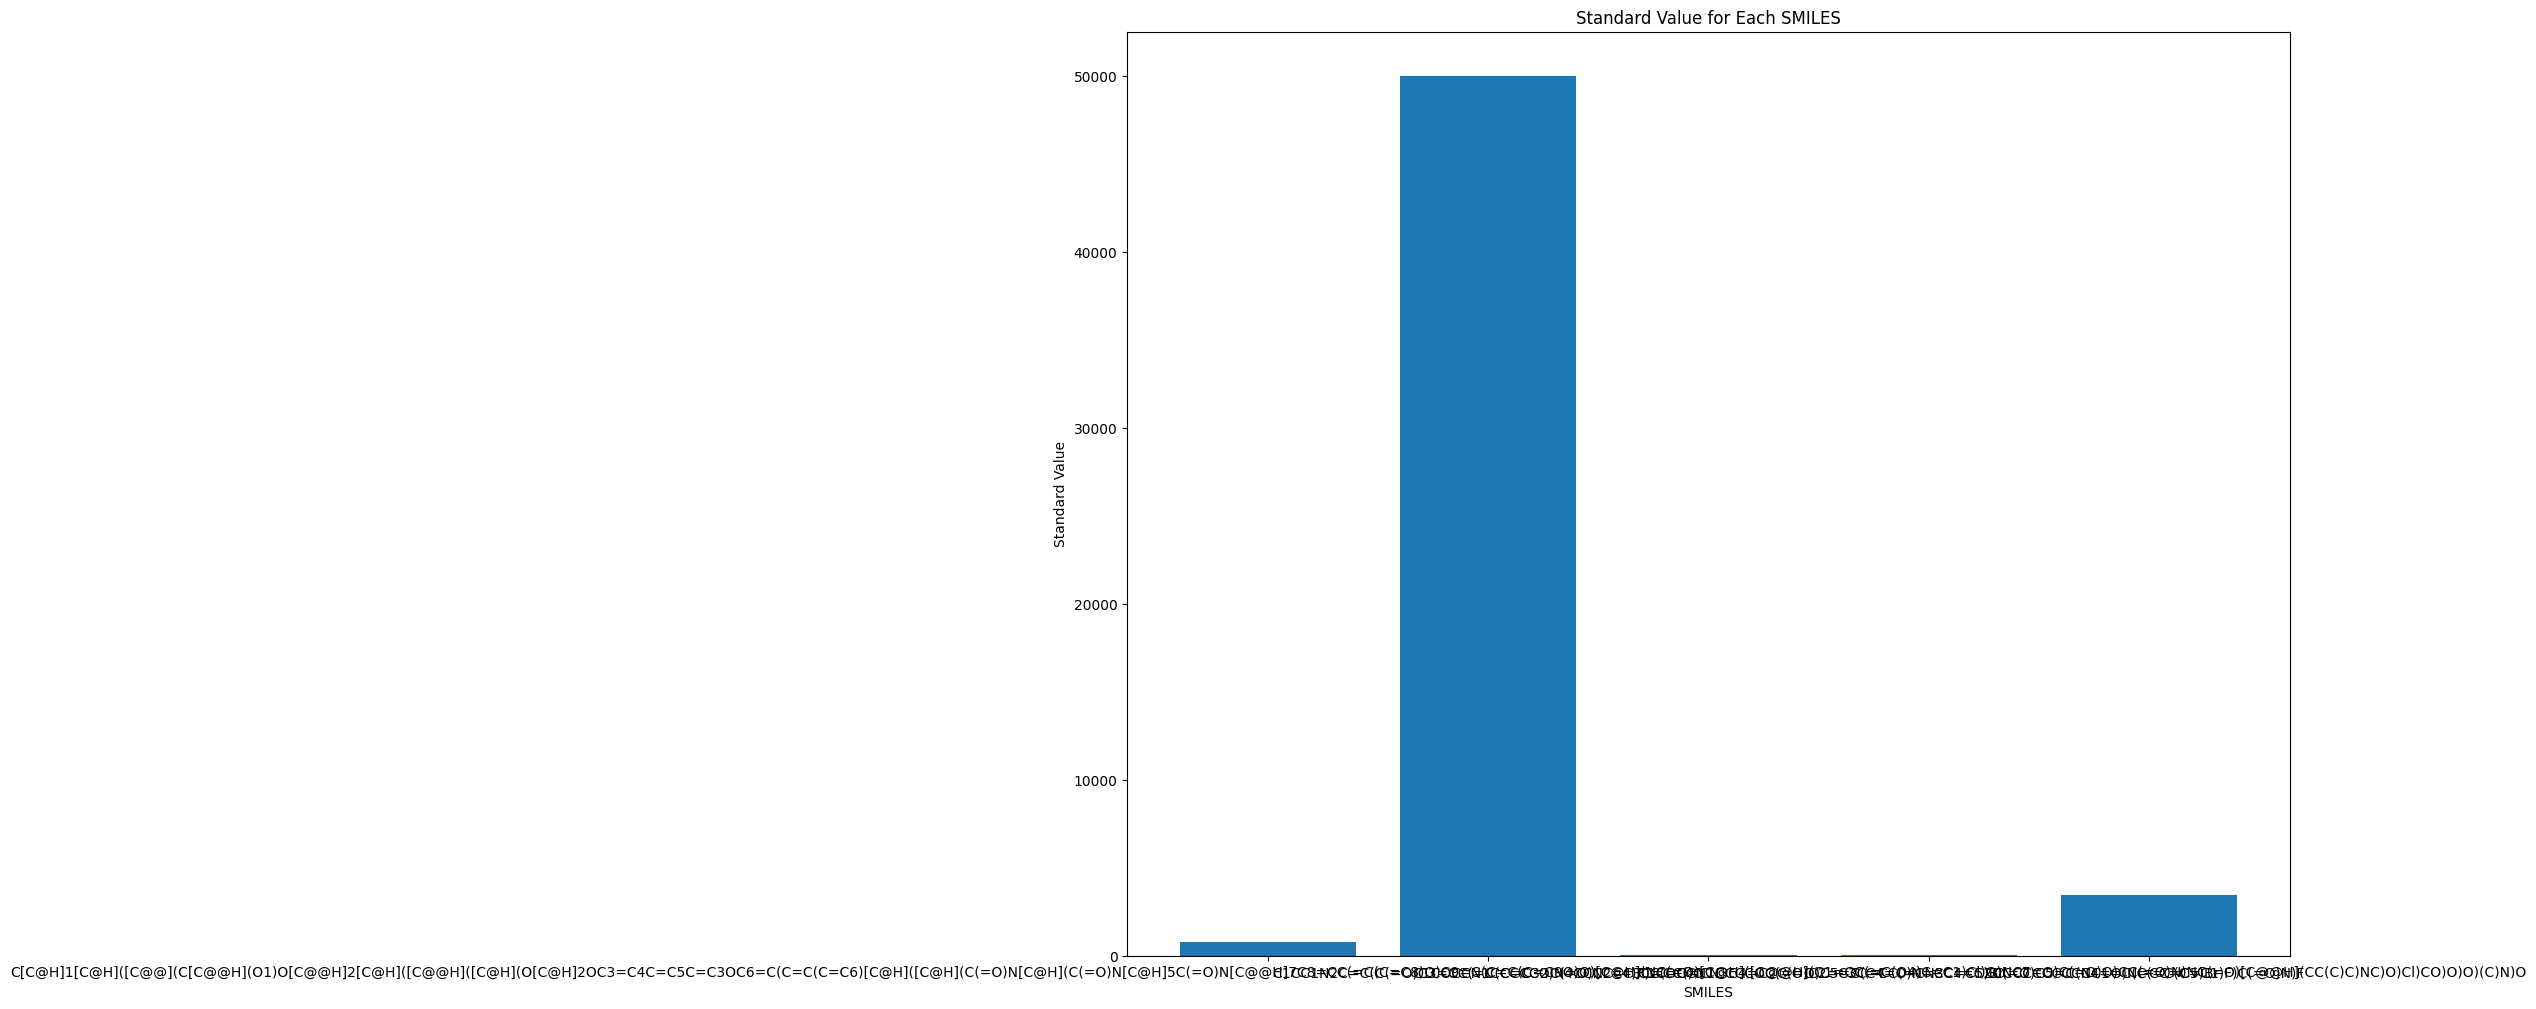

In [17]:
fig, ax = plt.subplots(figsize=(15,12))
ax.bar(df_subset['PUBCHEM_EXT_DATASOURCE_SMILES'], df_subset['Standard Value']);
ax.set(title="Standard Value for Each SMILES", xlabel="SMILES", ylabel="Standard Value");


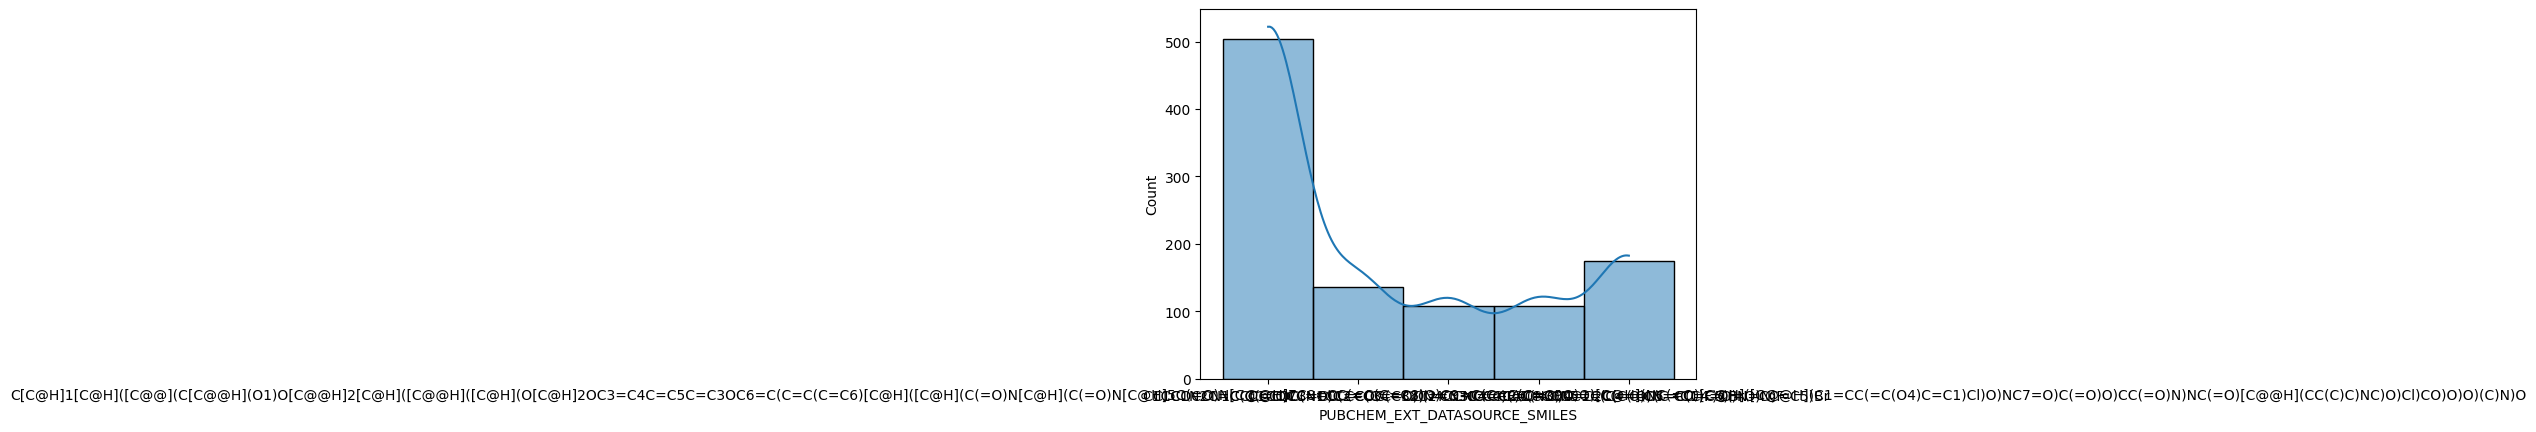

In [18]:
sns.histplot(df_subset['PUBCHEM_EXT_DATASOURCE_SMILES'], bins=30, kde=True);

In [33]:
df_subset.loc[(df_subset.PUBCHEM_EXT_DATASOURCE_SMILES == 'C[C@H]1[C@H]([C@@](C[C@@H](O1)O[C@@H]2[C@H]([C@@H]([C@H](O[C@H]2OC3=C4C=C5C=C3OC6=C(C=C(C=C6)[C@H]([C@H](C(=O)N[C@H](C(=O)N[C@H]5C(=O)N[C@@H]7C8=CC(=C(C=C8)O)C9=C(C=C(C=C9O)O)[C@H](NC(=O)[C@H]([C@@H](C1=CC(=C(O4)C=C1)Cl)O)NC7=O)C(=O)O)CC(=O)N)NC(=O)[C@@H](CC(C)C)NC)O)Cl)CO)O)O)(C)N)O'), ('Standard Value')].head()

188    1.380004
198    1.380004
209    0.690002
737    0.690002
743    5.520017
Name: Standard Value, dtype: float64

In [20]:
target_smile =  'C[C@H]1[C@H]([C@@](C[C@@H](O1)O[C@@H]2[C@H]([C@@H]([C@H](O[C@H]2OC3=C4C=C5C=C3OC6=C(C=C(C=C6)[C@H]([C@H](C(=O)N[C@H](C(=O)N[C@H]5C(=O)N[C@@H]7C8=CC(=C(C=C8)O)C9=C(C=C(C=C9O)O)[C@H](NC(=O)[C@H]([C@@H](C1=CC(=C(O4)C=C1)Cl)O)NC7=O)C(=O)O)CC(=O)N)NC(=O)[C@@H](CC(C)C)NC)O)Cl)CO)O)O)(C)N)O'
df_sub = (df_subset['PUBCHEM_EXT_DATASOURCE_SMILES'] == target_smile).sum()
print(df_sub)

504


In [21]:
df_subset['PUBCHEM_EXT_DATASOURCE_SMILES'].get('C[C@H]1[C@H]([C@@](C[C@@H](O1)O[C@@H]2[C@H]([C@@H]([C@H](O[C@H]2OC3=C4C=C5C=C3OC6=C(C=C(C=C6)[C@H]([C@H](C(=O)N[C@H](C(=O)N[C@H]5C(=O)N[C@@H]7C8=CC(=C(C=C8)O)C9=C(C=C(C=C9O)O)[C@H](NC(=O)[C@H]([C@@H](C1=CC(=C(O4)C=C1)Cl)O)NC7=O)C(=O)O)CC(=O)N)NC(=O)[C@@H](CC(C)C)NC)O)Cl)CO)O)O)(C)N)O', 0)

0

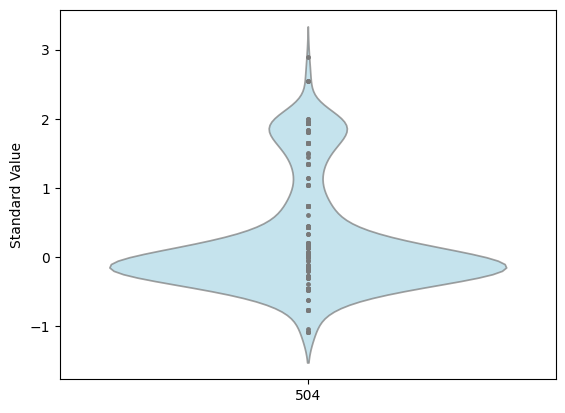

In [34]:
import pandas as pd
import numpy as np
import seaborn as sns

target_smile =  'C[C@H]1[C@H]([C@@](C[C@@H](O1)O[C@@H]2[C@H]([C@@H]([C@H](O[C@H]2OC3=C4C=C5C=C3OC6=C(C=C(C=C6)[C@H]([C@H](C(=O)N[C@H](C(=O)N[C@H]5C(=O)N[C@@H]7C8=CC(=C(C=C8)O)C9=C(C=C(C=C9O)O)[C@H](NC(=O)[C@H]([C@@H](C1=CC(=C(O4)C=C1)Cl)O)NC7=O)C(=O)O)CC(=O)N)NC(=O)[C@@H](CC(C)C)NC)O)Cl)CO)O)O)(C)N)O'
df_sub = df_subset[df_subset['PUBCHEM_EXT_DATASOURCE_SMILES'] == target_smile]

sns.violinplot(data=df_sub,
            x = (df_sub['PUBCHEM_EXT_DATASOURCE_SMILES'] == target_smile).sum(),
            y = np.log10(df_sub['Standard Value']),
            inner="point",
            split=False,
            saturation=1,
            alpha=0.7,
            color="lightblue");

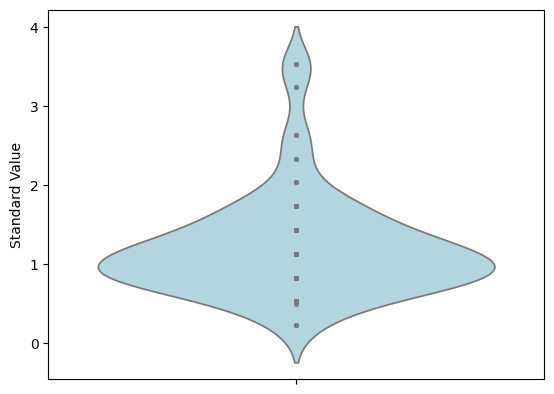

In [119]:
target_smile_2 = 'CCCCCCCCCNC1=C(C(=C(C=C1)F)C(=O)N)F'
df_sub_2 = df_subset[df_subset['PUBCHEM_EXT_DATASOURCE_SMILES'] == target_smile_2]
sns.violinplot( y = np.log10(df_sub_2['Standard Value']), 
               inner="point", 
               color="lightblue");

In [43]:
df_AT = pd.read_csv('pubchem_AT.xlsx - All.csv',  sep =',')
df_AT.info()

<class 'pandas.DataFrame'>
RangeIndex: 11829 entries, 0 to 11828
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  11829 non-null  str  
 1   SMILE       11829 non-null  str  
 2   Unnamed: 9  11829 non-null  str  
 3   MIC         11829 non-null  str  
 4   donvi       11829 non-null  str  
dtypes: str(5)
memory usage: 462.2 KB


In [44]:
df_AT['SMILE'].duplicated().sum()

np.int64(10146)

In [46]:
counts_AT = df_AT['SMILE'].value_counts()
duplicate_AT = counts_AT[counts_AT >= 2].sum() # Lấy tổng số dòng trùng lặp
print(f"Số lượng chất bị lặp trong df_AT: {duplicate_AT}")

Số lượng chất bị lặp trong df_AT: 11466
